In [1]:
import numpy as np
from sklearn.datasets import make_classification

X,y = make_classification(
    n_samples=30,
    n_features=2,
    n_classes=2,
    n_informative=2,
    n_redundant=0,
    n_repeated=0,
    shuffle=False
)

X = np.absolute(X)
X = np.round(X, 2) * 100
X = X.astype(int)

print(X)
print(y)

[[ 90 113]
 [111  84]
 [107  91]
 [ 26 198]
 [ 66 147]
 [164  16]
 [129  63]
 [152  32]
 [ 56 151]
 [115  44]
 [ 34 174]
 [ 56 137]
 [ 99 293]
 [133  27]
 [ 90 114]
 [107 127]
 [108 140]
 [213 293]
 [102 106]
 [ 55  60]
 [  5  78]
 [ 34  32]
 [170 233]
 [200  17]
 [174   9]
 [ 30 243]
 [ 16  95]
 [154  10]
 [169  45]
 [246  47]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


In [2]:
import pandas as pd

y_new = y.reshape(len(y), 1)
data = np.concatenate((X, y_new), axis=1)

nama_kolom = ['Feature 1', 'Feature 2', 'Label']

df = pd.DataFrame(data, columns=nama_kolom)

df.head()

,Feature 1,Feature 2,Label
0,90,113,0
1,111,84,0
2,107,91,0
3,26,198,0
4,66,147,0


In [3]:
labels = {
    1 : 'Class A',
    0 : 'Class B'
}

df_label = df.copy()
df_label['Label'] = df_label['Label'].map(labels)

df_label.head()

,Feature 1,Feature 2,Label
0,90,113,Class B
1,111,84,Class B
2,107,91,Class B
3,26,198,Class B
4,66,147,Class B


/tmp/ipykernel_575/3977962104.py:9: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Class A')
/tmp/ipykernel_575/3977962104.py:10: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Class B')


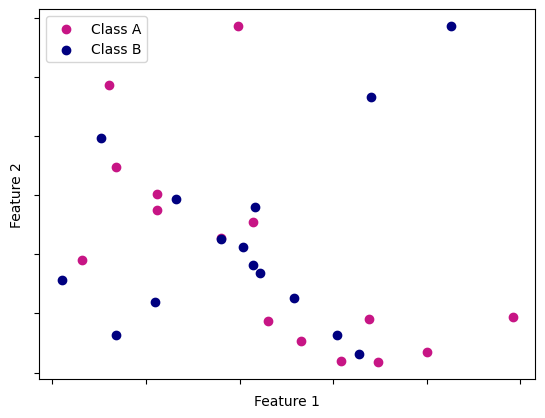

In [4]:
import matplotlib.pyplot as plt

colors = {
    'class_a': 'MediumVioletRed',
    'class_b': 'Navy'
}

gb = df_label.groupby(['Label'])
class_a = gb.get_group('Class A')
class_b = gb.get_group('Class B')

plt.scatter(x=class_a['Feature 1'], y=class_a['Feature 2'], c=colors['class_a'])
plt.scatter(x=class_b['Feature 1'], y=class_b['Feature 2'], c=colors['class_b'])
plt.xlabel('Feature 1'); plt.ylabel('Feature 2')
plt.legend(['Class A', 'Class B'])
plt.gca().axes.xaxis.set_ticklabels([])
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

In [5]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

mnb = MultinomialNB()

X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size=0.3, random_state=30
)

mnb.fit(X_train, y_train)

y_train_pred = mnb.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

y_test_pred = mnb.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Training accuracy: {acc_train}')
print(f'Test accuracy: {acc_test}')

Training accuracy: 0.7142857142857143
Test accuracy: 0.3333333333333333


In [6]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

y_train_pred_gnb = gnb.predict(X_train)
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

y_test_pred_gnb = gnb.predict(X_test)
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

print(f'Training accuracy (Gaussian): {acc_train_gnb}')
print(f'Test accuracy (Gaussian): {acc_test_gnb}')

Training accuracy (Gaussian): 0.6190476190476191
Test accuracy (Gaussian): 0.4444444444444444
